# Coding Exercise: PCA vs Total Variance

#### 1 Setup

In [1]:
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
from sklearn.decomposition import PCA

In [2]:
RANDOM_STATE = 42

# Configure NumPy.
rng = np.random.default_rng(seed=RANDOM_STATE)
np.set_printoptions(linewidth=100)

# Configure Seaborn.
sns.set_style("whitegrid")
sns.set_palette("deep")

In [3]:
digits = datasets.load_digits()
X = digits.data

#### 2 PC vs Total variance

In [4]:
var_threshold = 0.90
ncp_vals = list()
tot_vars = list()
var_thr_x = None  # X value that captures 95% variance.

n, d = X.shape

for n_components in range(1, d + 1):
    pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
    pca.fit(X)
    tot_variance = pca.explained_variance_ratio_.sum()

    if tot_variance >= var_threshold and var_thr_x == None:
        var_thr_x = n_components

    ncp_vals.append(n_components)
    tot_vars.append(tot_variance)

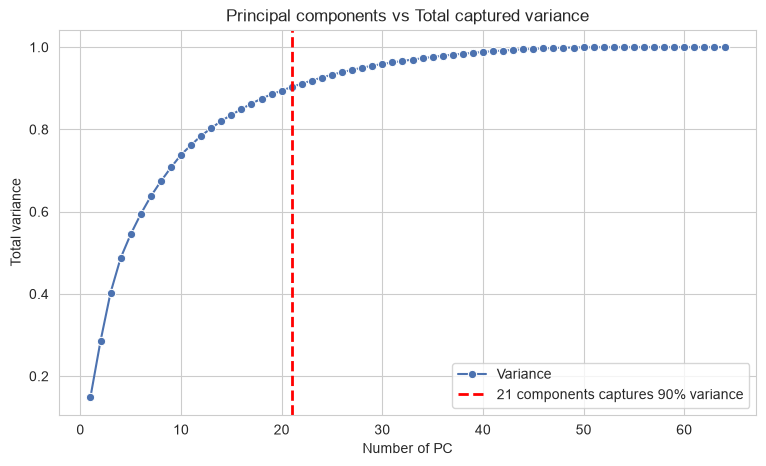

In [5]:
plt.figure(figsize=(9, 5))

var_per = round(var_threshold * 100)
nc_label = f"{var_thr_x} components captures {var_per}% variance"

ax = sns.lineplot(x=ncp_vals, y=tot_vars, marker="o", label="Variance")
ax.axvline(x=var_thr_x, color="red", linestyle="--", linewidth=2, label=nc_label)
plt.title("Principal components vs Total captured variance")
plt.xlabel("Number of PC")
plt.ylabel("Total variance")

plt.legend()
plt.show()

In [6]:
print(f"Number of principal components that are needed to capture {var_per}% of variance: {var_thr_x}")

Number of principal components that are needed to capture 90% of variance: 21
